# Entendendo Resultados Abaixo do Esperado - PBA Sergipe (2026)

## 1. Importação, Limpeza e Estruturação de Dados

Para iniciar a nossa análise sobre o desempenho dos alfabetizandos do Programa Brasil Alfabetizado (PBA) em Sergipe, precisamos primeiro preparar a nossa base de dados. O objetivo desta etapa é garantir a integridade da nossa análise, focando apenas no público que realmente participou da metodologia.

**Regras de Negócio Aplicadas:**
* **Renomear colunas:** Renomeiação de colunas que contenham nomes de colunas "ds_turmas" para "turma" para padronizar em todos os dfs.
* **Transformar Tipos de Dados:** Transformação de tipos de dados, como `object` para `category` e `datetime` para `date`.
* **Mapear Valores de Variáveis Categorizadas:** Mapeamento de variáveis categóricas para simplificar visualizações.
* **Melhorar strings:** Transformação de strings relacionados a avaliação Socioemocional para o formato esperado pelo projeto Alfabetiza Sergipe.
* **Unificação:** Cruzamento das informações pedagógicas com os dados logísticos das turmas (utilizando as colunas correspondentes de cada base).
* **Filtro de População:** Remoção de alfabetizandos com status `EVADIDO` e turmas com situação `Encerrada` ou `Aguardando início`, evitando que dados ruidosos deturpem os indicadores de desempenho.
* **Tratamento Geográfico:** Categorização de turmas sem localização informada.
* **Engenharia de Variáveis:** Criação da métrica de *Taxa de Frequência da Unidade 1*, focando especificamente no período que antecede a Avaliação Formativa 1.


In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings('ignore')

# 1. Carregamento dos dados
df_turmas = pd.read_csv('data_files/original_data/turmas_08102026.csv')
df_pedagogico = pd.read_csv('data_files/original_data/dados_pedagogicos_08102026.csv')

# Trocando nome de coluna nos dfs para melhorar merges
def renomear_colunas_turmas(df):
    """
    Renomeia colunas do de dfs que contenham colunas com nome "ds_turmas" para "turma" para padronizar em todos os dfs.
    """
    # Criamos uma cópia para evitar o SettingWithCopyWarning
    df_resultado = df.copy()
    
    # Renomeia as colunas
    df_resultado = df_resultado.rename(columns={'ds_turma': 'turma', 'turma_municipio': 'municipio'})
    
    return df_resultado

# Transformando tipo de dados object em dados mais representativos (categorias e datas)
# Definindo colunas categóricas para df_pedagogico
cols_categoricas = [
    "status_alfabetizando", "diag_entr_result",
    "socio_entr_q1", "socio_entr_q2", "socio_entr_q3", "socio_entr_q4", 
    "socio_entr_q5", "socio_entr_q6", "socio_entr_q7",
    "forma_1_result", "forma_2_result", "forma_3_result", 
    "forma_4_result", "diag_said_result", 
    "socio_said_q1", "socio_said_q2", "socio_said_q3", "socio_said_q4", 
    "socio_said_q5", "socio_said_q6", "socio_said_q7", "socio_said_q8", "socio_said_q9"
]

def transformar_dados_pba(df):
    """
    Realiza a limpeza e transformação de tipos para o projeto Alfabetiza Sergipe.
    """
    # Transformação de Categóricos (df_pedagogico)
    for col in cols_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')
            
    # Transformação de Datas (df_pedagogico)
    if 'dt_inicio_turma' in df.columns:
        df['dt_inicio_turma'] = pd.to_datetime(df['dt_inicio_turma'], dayfirst=True, errors='coerce')
        
    # Transformação de Datas (df_turmas)
    cols_datas_turmas = ["dt_inicio", "dt_fim", "data_situacao_turma", "dt_fim_previsao_f"]
    
    for col in cols_datas_turmas:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')
        
    print("Transformação concluída com sucesso!")
    return df

# Aplicando a função
df_pedagogico, df_turmas = [transformar_dados_pba(renomear_colunas_turmas(df)) for df in [df_pedagogico, df_turmas]]

# Checando resultados
print(df_pedagogico.info())
print(df_turmas.info())


Transformação concluída com sucesso!
Transformação concluída com sucesso!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8306 entries, 0 to 8305
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   cpf                         8306 non-null   object        
 1   alfabetizando               8306 non-null   object        
 2   dt_nascimento               8306 non-null   object        
 3   turma                       8306 non-null   object        
 4   municipio                   8306 non-null   object        
 5   status_alfabetizando        8306 non-null   category      
 6   dt_inicio_turma             8306 non-null   datetime64[ns]
 7   alfabetizador               8306 non-null   object        
 8   coordenador                 8306 non-null   object        
 9   qtd_aulas_dadas_turma       8306 non-null   int64         
 10  qtd_presenca_alfabetizando  7677 non-null   fl

In [114]:
# Vamos mapear textos para as variáveis categoricas e criar textos mais resumidos para facilitar a visualização e análise.
mapeamento_textos = {
    'Demonstra motivação constante e desejo de continuar estudando': 'Demosntra motivação', 
    'Demonstra interesse, mas com oscilações': 'Demonstra interesse', 
    'Demonstra desmotivação ou desejo de interromper': 'Demonstra desmotivação', 
    'São frequentes e pontuais': 'Frequentes e pontuais', 
    'Frequência regular sem nenhuma falta': 'Frequência sem faltas', 
    'Frequência regular com algumas faltas': 'Frequência com faltas', 
    'Realiza com alguma ajuda': 'Realiza com ajuda', 
    'Realiza com autonomia na maioria das situações': 'Realiza com autonomia',
    'Depende de ajuda constante': 'Depende de ajuda', 
    'Tenta com apoio e incentivo': 'Tenta com apoio',
    'Tenta com iniciativa própria': 'Tenta com iniciativa',
    'Demonstra insegurança e evita tentar': 'Demonstra insegurança', 
    'Persiste e aceita o erro como parte da aprendizagem': 'Persiste e aceita o erro',
    'Persiste, mas demonstra frustração': 'Persiste com frustração',
    'Desiste facilmente': 'Desiste facilmente', 
    'Participa ativamente e coopera com os colegas': 'Participa e coopera',
    'Participa quando estimulado(a)': 'Participa quando estimulado(a)',
    'Evita interações': 'Evita interações', 
    'Reconhece claramente e relata usos práticos': 'Reconhece claramente',
    'Reconhece em algumas situações': 'Reconhece algumas vezes',
    'Não reconhece': 'Não reconhece', 
    'Boa motivação e interesse constante': 'Boa motivação e interesse',
    'Baixa motivação e risco de evasão': 'Baixa motivação',
    'Frequência regular e boa permanência': 'Frequênte e permanente',
    'Frequência regular com algumas faltas': 'Frequênte com faltas',
    'Frequência irregular e evasões significativas': 'Frequênte irregular',
    'Realizou com autonomia em várias situações': 'Realizou com autonomia',
    'Realizou com alguma ajuda': 'Realizou com ajuda',
    'Dependeu de ajuda constante': 'Dependeu de ajuda',
    'Demonstrou iniciativa e envolvimento': 'Demonstrou iniciativa',
    'Tentou com incentivo': 'Tentou com incentivo',
    'Demonstrou insegurança e resistência': 'Com insegurança e resistência',
    'Persistiu e compreendeu o erro como parte da aprendizagem': 'Persistiu e superou',
    'Persistiu com apoio': 'Persistiu com apoio',
    'Desistiu com facilidade': 'Desistiu facilmente',
    'Participou e cooperou ativamente com os colegas': 'Participou ativamente',
    'Interagiu quando estimulado(a)': 'Interagiu sob estimulação',
    'Apresentou pouca interação': 'Apresentou pouca interação',
    'Reconhecimento claro e frequente com usos práticos': 'Reconhecimento frequente',
    'Reconhecimento parcial': 'Reconhecimento parcial',
    'Pouco reconhecimento': 'Pouco reconhecimento',
    'Predominância nos níveis mais avançados': 'Níveis avançados',
    'Distribuição equilibrada entre níveis': 'Distribuição entre níveis',
    'Predominância nos níveis iniciais': 'Níveis iniciais',
    'Foram superados': 'Foram superados',
    'Tentou com incentivo': 'Tentou com incentivo',
    'Não foram superados': 'Não foram superados',
    'N1 | Não reconhece as letras do alfabeto': 'N1',
    'N2 | Lê e registra algumas letras com ajuda, sem relação entre fala e escrita': 'N2',
    'N3 | Reconhece algumas letras do alfabeto': 'N3',
    'N4 | Identifica o número de sílabas de palavras com apoio': 'N4', 
    'N1 | Atenção à escuta e reconhecimento inicial de letras': 'N1', 
    'N2 | Reconhece letras e sílabas com apoio': 'N2',
    'N3 | Identifica sílabas, sem relação letra–som': 'N3',
    'N4 | Reconhece sílabas, sem leitura de palavras': 'N4',
    'N1 | Identifica sílabas com apoio e reconhece palavras simples sem leitura autônoma': 'N1',
    'N2 | Reconhece o número de sílabas e identifica sílabas iguais com apoio': 'N2',
    'N3 | Decodifica palavras formadas por sílabas simples de forma lenta e silabada, com apoio': 'N3',
    'N4 | Lê palavras simples, ainda sem fluência e sem autonomia, demonstrando avanço na relação letra–som': 'N4',
    'N1 | Lê e escreve poucas palavras conhecidas, sempre com apoio': 'N1',
    'N2 | Lê e escreve palavras simples com autonomia inicial e possíveis erros': 'N2',
    'N3 | Lê e escreve palavras e frases simples, com possíveis erros ortográficos': 'N3',
    'N4 | Lê e escreve frases simples com maior segurança, ainda sem fluência leitora': 'N4',
    'N1 | Lê e escreve palavras e frases curtas com apoio e escreve o próprio nome com segurança': 'N1',
    'N2 | Lê e escreve frases curtas e pequenos textos, mesmo com erros ortográficos, e compreende informações explícitas': 'N2',
    'N3 | Lê, escreve e interpreta pequenos textos com compreensão básica e possíveis erros': 'N3',
    'N4 | Lê, escreve, compreende e interpreta pequenos textos, com possíveis erros ortográficos e fluência leitora inicial': 'N4',
    'N1 | Reconhece letras e sílabas com apoio; registra palavras e o nome; relação inicial fala–escrita': 'N1',
    'N2 | Reconhece e conta sílabas; relaciona letra e som; lê palavras com sílabas simples': 'N2',
    'N3 | Lê palavras e frases simples; escreve palavras e frases com sentido, mesmo com erros ortográficos': 'N3',
    'N4 | Lê pequenos textos com compreensão; escreve palavras, frases e pequenos textos; demonstra autonomia na leitura e escrita': 'N4'
}

# Criar a novas colunas resumidas para cada coluna categórica usando o .map()
for coluna in cols_categoricas:
    df_pedagogico[coluna + '_resum'] = df_pedagogico[coluna].map(mapeamento_textos)

# Transformar em tipo Categórico (ordenado) somente as colunas com níveis
# Isso é importante para que em gráficos o N1 venha antes do N2, etc.
niveis_ordenados = ['N1', 'N2', 'N3', 'N4']
colunas_niveis = ['diag_entr_result_resum', 'forma_1_result_resum', 'forma_2_result_resum', 'forma_3_result_resum', 'forma_4_result_resum', 'diag_said_result_resum']

for coluna in colunas_niveis:
    df_pedagogico[coluna] = pd.Categorical(
        df_pedagogico[coluna], 
        categories=niveis_ordenados, 
        ordered=True
    )

# Removemos colchetes, aspas duplas, aspas simples da coluna socio_entr_q9 e depois dividimos por vírgula
# 1. Criamos uma função inteligente para transformar o texto em uma lista real do Python
def extrair_lista_q9(valor):
    # Se o valor for vazio (NaN), retorna lista vazia
    if pd.isna(valor):
        return []
    
    # Se por acaso já for uma lista, ótimo, apenas retorna
    if isinstance(valor, list):
        return valor
    
    # Limpa espaços em branco nas bordas
    texto = str(valor).strip()
    
    if not texto or texto.lower() == 'nan':
        return []
    
    try:
        # O json.loads pega '["Falta de confian\u00e7a em si"]' e transforma perfeitamente na lista ['Falta de confiança em si']
        # Caso o CSV tenha duplicado aspas (ex: "[""...""]"), corrigimos antes
        texto = texto.replace('""', '"')
        lista = json.loads(texto)
        
        # Retorna a lista garantindo que não há itens vazios soltos
        return [str(item).strip() for item in lista if str(item).strip()]
    except:
        # PLANO B: Se o json falhar por algum caractere estranho, limpamos na mão
        limpo = texto.replace('[', '').replace(']', '').replace('"', '').replace("'", "")
        return [item.strip() for item in limpo.split(',') if item.strip()]
    
# 2. Aplicamos a nossa função na coluna para criar a coluna com as listas reais
df_pedagogico['socio_entr_q8_resum'] = df_pedagogico['socio_entr_q9'].apply(extrair_lista_q9)

# Verificando os tipos de dados e informações das colunas
print(df_pedagogico.info())
display(df_pedagogico.head())
display(df_pedagogico[['socio_entr_q9', 'socio_entr_q8_resum']].head())
print(df_pedagogico['socio_entr_q8_resum'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8306 entries, 0 to 8305
Columns: 113 entries, cpf to socio_entr_q8_resum
dtypes: category(44), datetime64[ns](1), float64(43), int64(9), object(16)
memory usage: 4.7+ MB
None


,cpf,alfabetizando,dt_nascimento,turma,municipio,status_alfabetizando,dt_inicio_turma,alfabetizador,coordenador,qtd_aulas_dadas_turma,...,socio_said_q1_resum,socio_said_q2_resum,socio_said_q3_resum,socio_said_q4_resum,socio_said_q5_resum,socio_said_q6_resum,socio_said_q7_resum,socio_said_q8_resum,socio_said_q9_resum,socio_entr_q8_resum
0,038.574.055-70,JOSINETE LIMA DE MELO,11/10/1982,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[Dificuldade ao falar]
1,934.917.275-53,JURACY DA SILVA,18/10/1977,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
2,095.351.555-98,WESLEY HULGO GONÇALVES EVANGELISTA,25/06/2008,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
3,007.660.805-01,ROBERTO DA SILVA LIMA,06/03/1979,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
4,117.493.585-57,ELOISA DE CARVALHO SANTOS,22/01/2006,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]


,socio_entr_q9,socio_entr_q8_resum
0,"[""Dificuldade ao falar""]",[Dificuldade ao falar]
1,NaN,[]
2,NaN,[]
3,NaN,[]
4,NaN,[]


socio_entr_q8_resum
[]                                                                                                                                                                                                                                                                                          3041
[Dificuldade ao falar]                                                                                                                                                                                                                                                                       788
[Falta de confian\u00e7a em si]                                                                                                                                                                                                                                                              601
[Habilidades motoras]                                                                                            

In [115]:
# 2. União das bases (Merge)
# Utilizando left_on e right_on para colunas com nomes distintos
df = pd.merge(df_pedagogico, df_turmas, on='turma', how='inner')

# 3. Filtros de População (Regras de Negócio)
# Remover alfabetizandos evadidos
df_limpo = df[df['status_alfabetizando'] != 'EVADIDO'].copy()

# Remover turmas encerradas ou aguardando início
turmas_invalidas = ['Encerrada', 'Aguardando início']
df_limpo = df_limpo[~df_limpo['situacao_turma'].isin(turmas_invalidas)]

# 4. Tratamento de Dados (Valores Vazios)
# Preencher valores vazios na localização
if 'ds_localizacao' in df_limpo.columns:
    df_limpo['ds_localizacao'] = df_limpo['ds_localizacao'].fillna('Não Informado')

# 5. Engenharia de Features
# Criar taxa de frequência da unidade 1 (com tratamento para evitar divisão por zero)
df_limpo['taxa_frequencia_unidade_1'] = np.where(
    df_limpo['qtd_aulas_1'] > 0, 
    df_limpo['qtd_presenca_1'] / df_limpo['qtd_aulas_1'], 
    0
)

# Visualizar o resultado do tratamento
registros_iniciais = df.shape[0]
registros_finais = df_limpo.shape[0]
print(f"Total de registos originais: {registros_iniciais}")
print(f"Total de registos válidos para análise: {registros_finais}")
print(f"Foram removidos {registros_iniciais - registros_finais} registos com base nas regras de negócio.")

# Visualizar as 5 primeiras linhas da base pronta
display(df_limpo.head())


Total de registos originais: 8306
Total de registos válidos para análise: 6148
Foram removidos 2158 registos com base nas regras de negócio.


,cpf,alfabetizando,dt_nascimento,turma,municipio_x,status_alfabetizando,dt_inicio_turma,alfabetizador_x,coordenador_x,qtd_aulas_dadas_turma,...,coordenador_y,alfabetizador_y,dt_inicio,dt_fim,situacao_turma,data_situacao_turma,dt_fim_previsao_f,ds_funcionamento,ds_localizacao,taxa_frequencia_unidade_1
6,093.800.125-60,LÁZARO VINICIUS DA SILVA RODRIGUES,23/09/1997,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,ANA MANUELA PEREIRA LIMA,INGRID LIMA DA SILVA,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.642857
7,009.346.975-66,ZEILDA ANDRADE DE OLIVEIRA,26/09/1977,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,ANA MANUELA PEREIRA LIMA,INGRID LIMA DA SILVA,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.928571
8,004.641.875-08,DIVANETE SILVA SANTOS,01/02/1967,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,ANA MANUELA PEREIRA LIMA,INGRID LIMA DA SILVA,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.714286
9,114.805.465-00,JOSE WEDISON DOS SANTOS PINTO,05/09/2008,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,ANA MANUELA PEREIRA LIMA,INGRID LIMA DA SILVA,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.571429
10,069.252.535-16,TAISE PAIXÃO DE LIMA,25/05/1995,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,INGRID LIMA DA SILVA,ANA MANUELA PEREIRA LIMA,60,...,ANA MANUELA PEREIRA LIMA,INGRID LIMA DA SILVA,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,1.000000


## 2. O Cenário Atual: O Problema na Formativa 1

A diretriz pedagógica do Programa Brasil Alfabetizado estabelece que, para considerarmos a metodologia efetivamente absorvida, **mais de 90% dos alfabetizandos devem atingir os níveis 3 ou 4 nas avaliações formativas**.

Nesta seção, realizamos um diagnóstico do cenário atual utilizando os resultados da **Formativa 1**. O gráfico a seguir ilustra a distribuição dos alunos por nível de aprendizado. Utilizamos um código de cores para facilitar a interpretação: em cinza, destacamos os níveis onde as práticas não foram plenamente adquiridas (Níveis 1 e 2), e em azul, destacamos os níveis satisfatórios (Níveis 3 e 4). 

Isso nos permitirá visualizar de forma clara o quão distantes estamos da meta estipulada e dimensionar o esforço necessário para as próximas etapas.


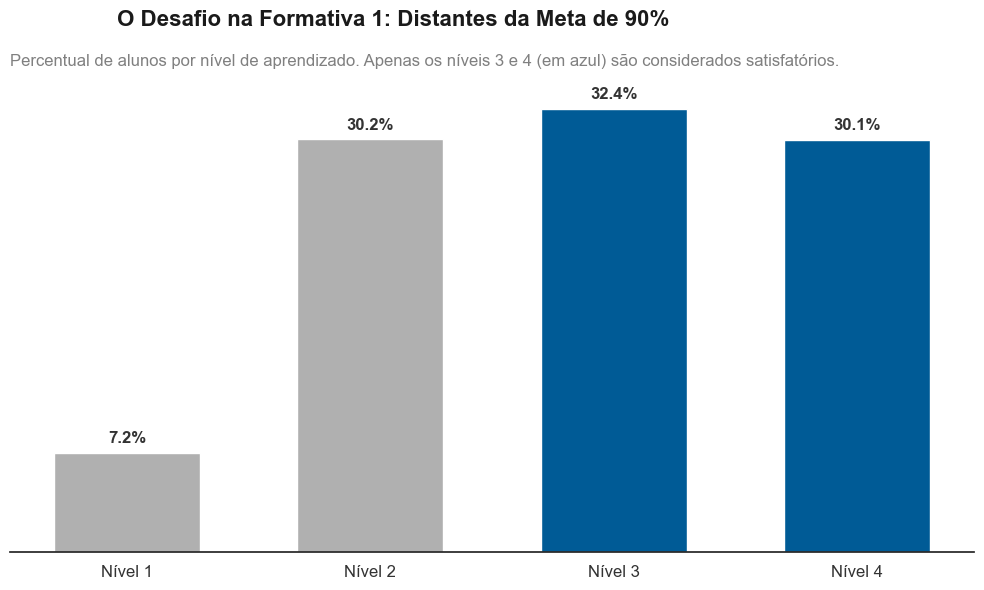

RESUMO EXECUTIVO:
-> 62.6% dos alfabetizandos atingiram os níveis 3 e 4 (Soma de 32.4% do N3 com 30.1% do N4).
-> Faltam 27.4 pontos percentuais para atingir a meta estipulada pelo programa (90%).


In [116]:
# Configurando o estilo do Seaborn para um visual limpo (sem fundo cinza ou grades)
sns.set_theme(style="white")

# CORREÇÃO: Utilizando a coluna '_resum' criada por você
df_plot = df_limpo.dropna(subset=['forma_1_result_resum']).copy()

# Calculando a porcentagem de alunos em cada nível usando a coluna correta
distribuicao = df_plot['forma_1_result_resum'].value_counts(normalize=True).sort_index() * 100

# Criando a figura e o eixo
fig, ax = plt.subplots(figsize=(10, 6))

# Definindo cores estratégicas (Storytelling): 
# Cinza para evidenciar o problema (Níveis 1 e 2), Azul para o sucesso (Níveis 3 e 4)
cores = ['#B0B0B0', '#B0B0B0', '#005b96', '#005b96']

# Plotando as barras
barras = ax.bar(distribuicao.index.astype(str), distribuicao.values, color=cores, width=0.6)

# Aplicando princípios de Storytelling com Dados
sns.despine(left=True, bottom=False)
ax.get_yaxis().set_visible(False)

# Adicionando os rótulos de dados diretamente no topo das barras
for barra in barras:
    altura = barra.get_height()
    # Verificação de segurança para não quebrar a anotação se a barra estiver vazia
    if pd.notnull(altura) and altura > 0:
        ax.annotate(f'{altura:.1f}%',
                    xy=(barra.get_x() + barra.get_width() / 2, altura),
                    xytext=(0, 5),  # Deslocamento vertical de 5 pontos
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=12, fontweight='bold', color='#333333')

# Configurando o eixo X para melhor legibilidade
ax.set_xticks(range(len(distribuicao.index)))
ax.set_xticklabels(['Nível 1', 'Nível 2', 'Nível 3', 'Nível 4'], fontsize=12, color='#333333')
ax.set_xlabel('')

# Título e Subtítulo orientados à narrativa (alinhados à esquerda)
plt.suptitle('O Desafio na Formativa 1: Distantes da Meta de 90%', fontsize=16, fontweight='bold', x=0.125, ha='left', color='#1a1a1a')
plt.title('Percentual de alunos por nível de aprendizado. Apenas os níveis 3 e 4 (em azul) são considerados satisfatórios.', fontsize=12, color='grey', loc='left', pad=15)

plt.tight_layout()
plt.show()

# Calculando e imprimindo o resumo consolidado com as categorias limpas
atingiram_meta = distribuicao.get('N3', 0) + distribuicao.get('N4', 0)

print("RESUMO EXECUTIVO:")
print(f"-> {atingiram_meta:.1f}% dos alfabetizandos atingiram os níveis 3 e 4 (Soma de {distribuicao.get('N3', 0):.1f}% do N3 com {distribuicao.get('N4', 0):.1f}% do N4).")
print(f"-> Faltam {90 - atingiram_meta:.1f} pontos percentuais para atingir a meta estipulada pelo programa (90%).")



### Síntese do Cenário Atual: O Tamanho do Desafio

O gráfico acima materializa e quantifica o nosso problema de negócio[cite: 17]. A diretriz do Programa Brasil Alfabetizado é garantir que pelo menos 90% dos alunos alcancem os níveis satisfatórios (Níveis 3 e 4) na avaliação. No entanto, os resultados da Formativa 1 revelam que o Nível 3 atingiu 32,4% e o Nível 4 alcançou 30,1%. Somando esses valores, temos atualmente **62,5%** dos alunos nos níveis desejados.

Isso significa que existe um **déficit de 27,5 pontos percentuais** para alcançarmos a meta estipulada pelo programa. 

Outro ponto de atenção recai sobre o Nível 2, que concentra de forma expressiva 30,2% dos alfabetizandos. Esse volume indica que quase um terço da base iniciou o processo de aprendizagem, mas estagnou antes de consolidar as práticas de linguagem exigidas pela Unidade 1. A defasagem mais crítica, o Nível 1, retém ainda 7,2% dos alunos.

Com o tamanho do gargalo devidamente dimensionado, a próxima pergunta natural a ser respondida pela nossa análise é: *Quais fatores estão prendendo 37,4% dos nossos alunos nos níveis insatisfatórios?* É exatamente isso que passaremos a investigar.

## 3. Raio-X do Alfabetizando: Perfil de Entrada e Fatores Socioemocionais

Para entender o não atingimento da meta na Formativa 1, precisamos investigar quem são os alunos com maiores dificuldades. A metodologia atual está a falhar de forma homogênea ou penaliza perfis específicos? 

Nesta etapa, realizamos análises de correlação em duas frentes fundamentais:
1. **A Matriz de Evolução (Diagnóstica vs. Formativa 1):** Comparamos o nível de conhecimento prévio do aluno com o seu resultado atual, medindo a real capacidade do programa de "resgatar" os alunos que chegam com as maiores defasagens (Nível 1).
2. **O Mapa Comportamental:** Avaliamos as 7 dimensões analisadas pelos educadores no Relatório Socioemocional. O objetivo é mapear qual comportamento atitudinal (como a autonomia, a reação ao erro ou a capacidade de interagir em grupo) tem maior peso probabilístico no sucesso ou no fracasso na avaliação de práticas.


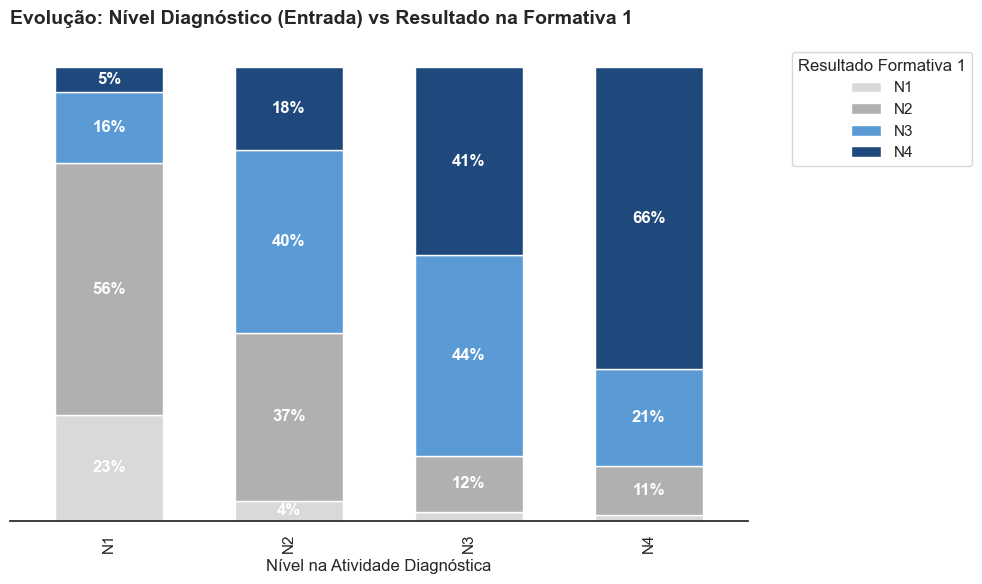

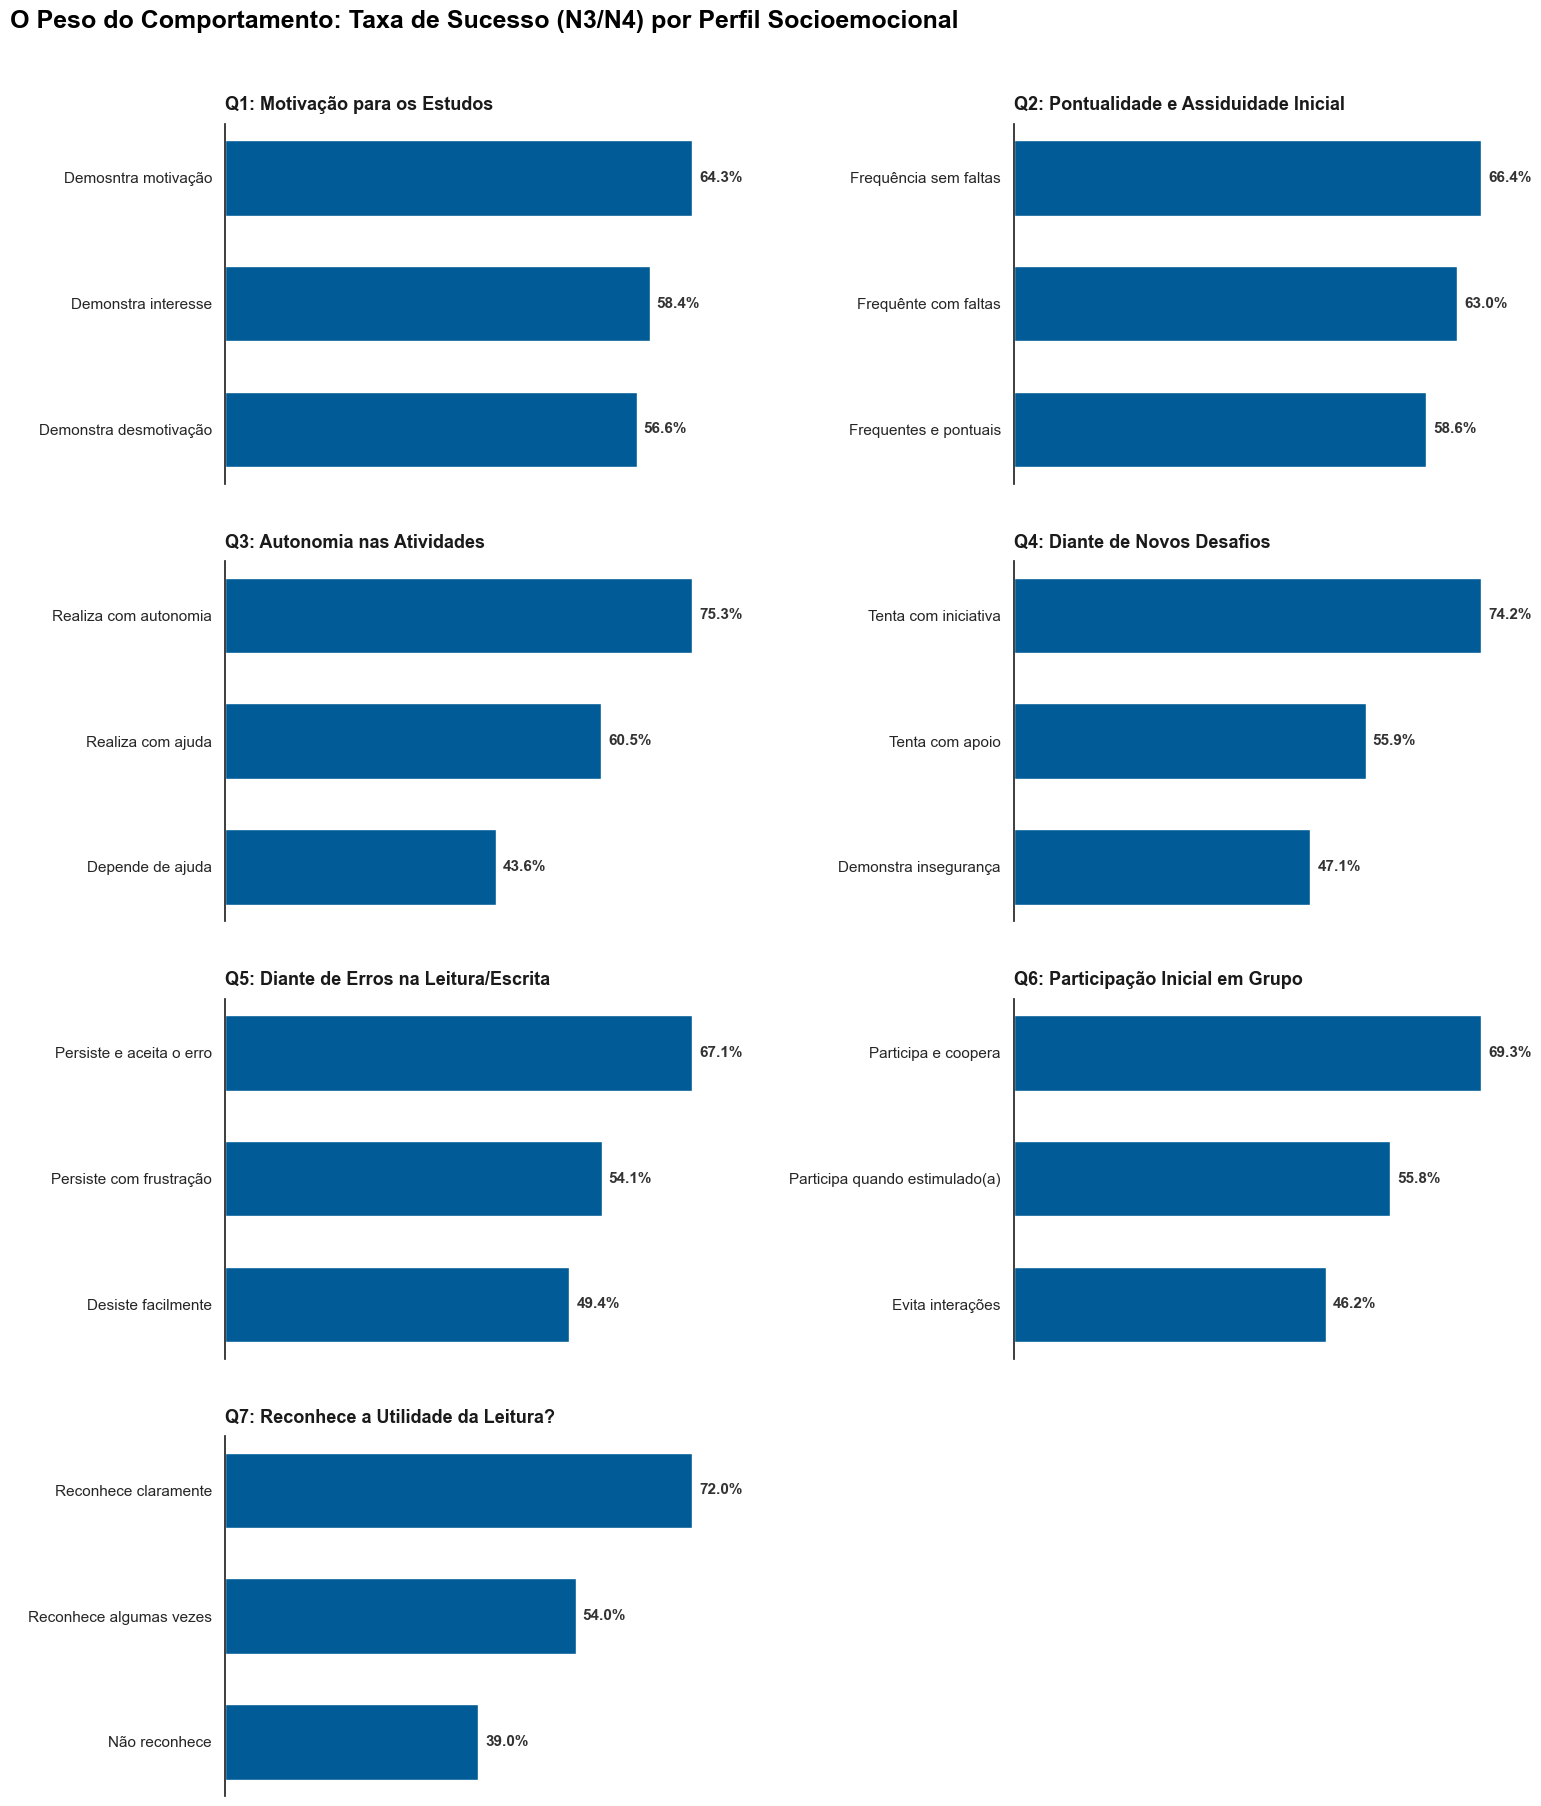

In [117]:
# Configuração visual padrão
sns.set_theme(style="white")

# ===================================================================
# PARTE 1: MATRIZ DE EVOLUÇÃO (Diagnóstica vs Formativa 1)
# ===================================================================
df_diag = df_limpo.dropna(subset=['diag_entr_result_resum', 'forma_1_result_resum']).copy()
cross_diag = pd.crosstab(df_diag['diag_entr_result_resum'], df_diag['forma_1_result_resum'], normalize='index') * 100

fig1, ax1 = plt.subplots(figsize=(10, 6))
cross_diag.plot(kind='bar', stacked=True, color=['#d9d9d9', '#b0b0b0', '#5b9bd5', '#1f497d'], ax=ax1, width=0.6)
sns.despine(ax=ax1, left=True)
ax1.get_yaxis().set_visible(False)
ax1.set_title('Evolução: Nível Diagnóstico (Entrada) vs Resultado na Formativa 1', loc='left', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Nível na Atividade Diagnóstica', fontsize=12)
ax1.legend(title='Resultado Formativa 1', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adicionando rótulos internos no Gráfico 1 (ocultando zeros)
for c in ax1.containers:
    labels = [f'{w:.0f}%' if w > 4 else '' for w in c.datavalues]
    ax1.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# ===================================================================
# PARTE 2: PAINEL SOCIOEMOCIONAL COMPLETO (7 Dimensões)
# ===================================================================
# Dicionário com as colunas e os temas de cada questão para os títulos dos gráficos
temas_socio = {
    'socio_entr_q1_resum': 'Q1: Motivação para os Estudos',
    'socio_entr_q2_resum': 'Q2: Pontualidade e Assiduidade Inicial',
    'socio_entr_q3_resum': 'Q3: Autonomia nas Atividades',
    'socio_entr_q4_resum': 'Q4: Diante de Novos Desafios',
    'socio_entr_q5_resum': 'Q5: Diante de Erros na Leitura/Escrita',
    'socio_entr_q6_resum': 'Q6: Participação Inicial em Grupo',
    'socio_entr_q7_resum': 'Q7: Reconhece a Utilidade da Leitura?'
}

df_socio = df_limpo.dropna(subset=['forma_1_result_resum']).copy()
df_socio['sucesso_f1'] = df_socio['forma_1_result_resum'].isin(['N3', 'N4']).astype(int) * 100

# Criando um grid de subplots: 4 linhas e 2 colunas
fig2, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

# Iterando sobre cada questão para gerar o gráfico correspondente
for i, (coluna, tema) in enumerate(temas_socio.items()):
    df_temp = df_socio.dropna(subset=[coluna])
    # Calcula a taxa de sucesso média para cada resposta daquela pergunta
    sucesso_q = df_temp.groupby(coluna, observed=True)['sucesso_f1'].mean().sort_values()
    
    ax = axes[i]
    barras = ax.barh(sucesso_q.index.astype(str), sucesso_q.values, color='#005b96', height=0.6)
    
    # Storytelling visual: removendo bordas
    sns.despine(ax=ax, bottom=True)
    ax.get_xaxis().set_visible(False)
    ax.set_title(tema, loc='left', fontsize=13, fontweight='bold', pad=10, color='#1a1a1a')
    ax.set_ylabel('')
    
    # Inserindo o valor percentual diretamente na ponta de cada barra
    for barra in barras:
        largura = barra.get_width()
        if pd.notnull(largura) and largura > 0:
            ax.annotate(f'{largura:.1f}%',
                        xy=(largura, barra.get_y() + barra.get_height() / 2),
                        xytext=(5, 0), textcoords="offset points",
                        ha='left', va='center', fontsize=11, fontweight='bold', color='#333333')

# Removendo o 8º gráfico que sobra (já que temos 7 questões e uma grade de 4x2)
fig2.delaxes(axes[7])

plt.tight_layout(pad=3.0)
plt.suptitle('O Peso do Comportamento: Taxa de Sucesso (N3/N4) por Perfil Socioemocional', 
             fontsize=18, fontweight='bold', x=0.02, y=1.02, ha='left', color='#000000')
plt.show()


### Síntese dos Diagnósticos: O Ponto de Partida e a Utilidade Prática

A quebra dos dados revela que o desafio da Formativa 1 não é homogêneo, mas sim altamente concentrado em perfis específicos de alunos. Os gráficos acima nos trazem dois insights de altíssimo impacto para a coordenação pedagógica:

**1. O Abismo do Ponto de Partida (A Matriz de Evolução)**
O programa apresenta um "teto de vidro" metodológico para alunos que ingressam com defasagem severa. 
* Apenas **21%** dos alfabetizandos que entraram no Nível 1 conseguiram atingir o patamar satisfatório (soma dos 16% no N3 com 5% no N4). 
* Em contrapartida, a taxa de sucesso salta para **87%** (21% + 66%) entre os alunos que já iniciaram no Nível 4.
* **Diagnóstico:** O ritmo ou a densidade do material da Unidade 1 não está permitindo que o aluno "N1" (absolutamente leigo) tenha tempo ou suporte suficiente para absorver o conteúdo antes da primeira avaliação.

**2. O Fator Comportamental: A Prática supera a "Motivação"**
O Painel Socioemocional quebra o mito de que o problema é apenas "falta de vontade". A diferença de sucesso entre um aluno motivado e um desmotivado (Q1) é pequena (64,3% vs 56,6%). Os verdadeiros sabotadores do aprendizado são estruturais e estão nas perguntas Q3, Q4 e Q7:
* **Conexão com a Realidade (Q7):** Este é o maior abismo do projeto. Alunos que não reconhecem a utilidade da leitura têm apenas **39%** de sucesso, contra **72%** daqueles que enxergam seu uso prático (um *gap* brutal de 33 pontos percentuais).
* **Dependência e Insegurança (Q3 e Q4):** Alunos que dependem de ajuda constante (43,6%) ou que evitam tentar novos desafios (47,1%) possuem taxas de aprovação majoritariamente fracassadas.
* **Diagnóstico:** A coordenação não deve cobrar dos professores que "motivem" mais as turmas, mas sim que **contextualizem** o ensino. O aluno adulto só aprende quando entende a utilidade prática da leitura para o seu dia a dia.

## 4. Fatores Logísticos, Geográficos e de Engajamento

O processo de alfabetização não ocorre no vácuo; ele é afetado pelo ambiente ao redor do aluno e do educador. Após compreendermos o perfil de entrada e a motivação, precisamos testar a influência de três variáveis operacionais:

1. **Localização (Urbana vs. Rural):** O contexto de infraestrutura e acesso influencia os resultados de aprendizagem?
2. **Frequência Específica (Unidade 1):** Qual o verdadeiro "custo" de uma falta? O engajamento físico nas aulas é um divisor de águas entre o sucesso e o baixo desempenho?
3. **Tamanho da Turma:** Existe um limite logístico de alunos em sala a partir do qual a metodologia perde eficácia, possivelmente devido à menor atenção individualizada do alfabetizador?

Abaixo, visualizamos essas três frentes de análise para compreender os gargalos operacionais do programa.


In [118]:
# Verificando turmas e alfabetizandos com número de presença maior que número de aulas (o que não faz sentido)
#df_presencas = df_limpo[['cpf', 'alfabetizando', 'dt_nascimento', 'turma', 'municipio_x', 'status_alfabetizando', 'dt_inicio_turma', 'alfabetizador_x', 'coordenador_x', 'qtd_aulas_dadas_turma', 'qtd_presenca_alfabetizando', 'qtd_presenca_1', 'qtd_presenca_2', 'qtd_presenca_3', 'qtd_presenca_4', 'qtd_aulas_1', 'qtd_aulas_2', 'qtd_aulas_3', 'qtd_aulas_4', 'ch_registrada_1', 'ch_registrada_2', 'ch_registrada_3', 'ch_registrada_4', 'ch_presenca_1', 'ch_presenca_2', 'ch_presenca_3', 'ch_presenca_4', 'ch_presenca_total']]
#df_presencas['frequencia_1'] = (df_presencas['qtd_presenca_1'] / df_presencas['qtd_aulas_1'])*100
#df_alunos_errados = df_presencas[df_presencas['frequencia_1'] > 100]
#display(df_alunos_errados[['cpf', 'alfabetizando', 'turma', 'municipio_x', 'status_alfabetizando', 'dt_inicio_turma', 'alfabetizador_x', 'coordenador_x', 'qtd_presenca_1','qtd_aulas_1' , 'frequencia_1']].sort_values('frequencia_1', ascending=False))
#print(df_alunos_errados['turma'].value_counts())


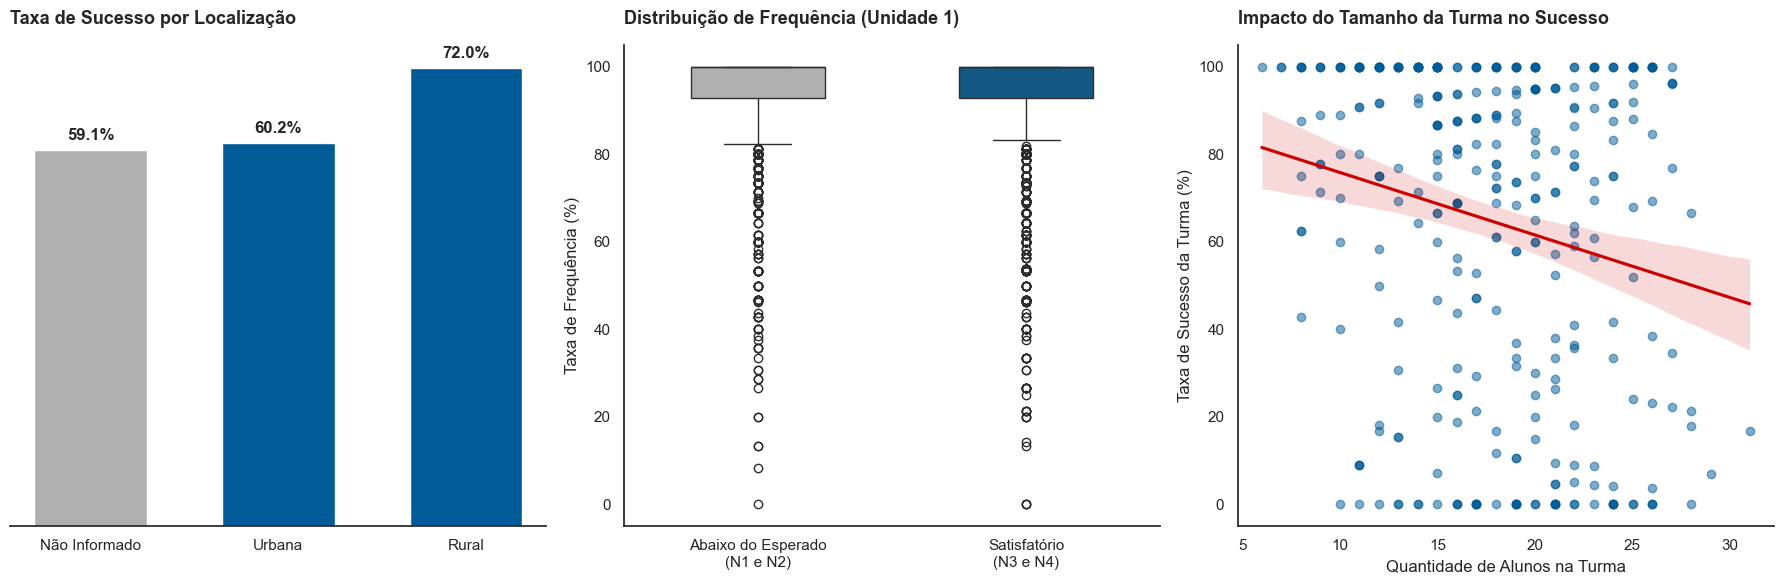

In [119]:
# Configuração visual padrão
sns.set_theme(style="white")

# 1. Preparação de Dados
# Filtrando apenas os que realizaram a Formativa 1 e criando a variável de sucesso binária
df_plot = df_limpo.dropna(subset=['forma_1_result_resum']).copy()
df_plot['sucesso_f1'] = df_plot['forma_1_result_resum'].isin(['N3', 'N4']).astype(int)
df_plot['taxa_freq_pct'] = df_plot['taxa_frequencia_unidade_1'] * 100
df_plot = df_plot[df_plot['taxa_freq_pct'] <= 100]

# 2. Configurando a Figura com 3 subgráficos (1 linha, 3 colunas)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# --- GRÁFICO 1: Fator Geográfico (Localização) ---
sucesso_loc = df_plot.groupby('ds_localizacao')['sucesso_f1'].mean().sort_values() * 100
# Destaque em azul para Rural e Urbana, e cinza para "Não Informado"
cores_loc = ['#b0b0b0' if loc == 'Não Informado' else '#005b96' for loc in sucesso_loc.index]

ax1.bar(sucesso_loc.index, sucesso_loc.values, color=cores_loc, width=0.6)
sns.despine(ax=ax1, left=True)
ax1.get_yaxis().set_visible(False)
ax1.set_title('Taxa de Sucesso por Localização', loc='left', fontsize=13, fontweight='bold', pad=15)

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# --- GRÁFICO 2: Engajamento (Frequência) ---
# Boxplot para mostrar a distribuição da frequência entre quem atingiu a meta e quem não atingiu
sns.boxplot(data=df_plot, x='sucesso_f1', y='taxa_freq_pct', palette=['#b0b0b0', '#005b96'], width=0.5, ax=ax2)
sns.despine(ax=ax2)
ax2.set_title('Distribuição de Frequência (Unidade 1)', loc='left', fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Abaixo do Esperado\n(N1 e N2)', 'Satisfatório\n(N3 e N4)'])
ax2.set_xlabel('')
ax2.set_ylabel('Taxa de Frequência (%)')

# --- GRÁFICO 3: Logística (Tamanho da Turma) ---
# Agrupando os dados por turma para ver a taxa de sucesso da turma inteira vs tamanho da sala
turmas_agg = df_plot.groupby('turma').agg(
    sucesso_rate=('sucesso_f1', lambda x: x.mean() * 100),
    tamanho_turma=('qtd_alfabetizandos', 'first')
).reset_index()

sns.regplot(data=turmas_agg, x='tamanho_turma', y='sucesso_rate', ax=ax3, 
            scatter_kws={'alpha': 0.5, 'color': '#005b96'}, line_kws={'color': '#cc0000'})
sns.despine(ax=ax3)
ax3.set_title('Impacto do Tamanho da Turma no Sucesso', loc='left', fontsize=13, fontweight='bold', pad=15)
ax3.set_xlabel('Quantidade de Alunos na Turma')
ax3.set_ylabel('Taxa de Sucesso da Turma (%)')

plt.tight_layout()
plt.show()


## 5. O Fator Educador: A Didática e a Dispersão por Turma

Uma das hipóteses levantadas para justificar o não atingimento da meta na Formativa 1 é a didática ou a experiência do alfabetizador. 

Para testar essa hipótese de forma justa, agrupamos os resultados por educador e calculamos a taxa de sucesso (alunos nos Níveis 3 ou 4) de suas respectivas turmas. O gráfico abaixo é um **Histograma de Dispersão**. Ele nos mostra quantos educadores conseguiram alcançar determinadas faixas de aprovação. 

Adicionamos duas linhas de referência cruciais: a **Média Atual** da rede e a **Meta do Programa (90%)**. A forma dessa curva nos dirá se estamos lidando com casos isolados de baixa performance ou com um desafio metodológico sistêmico.


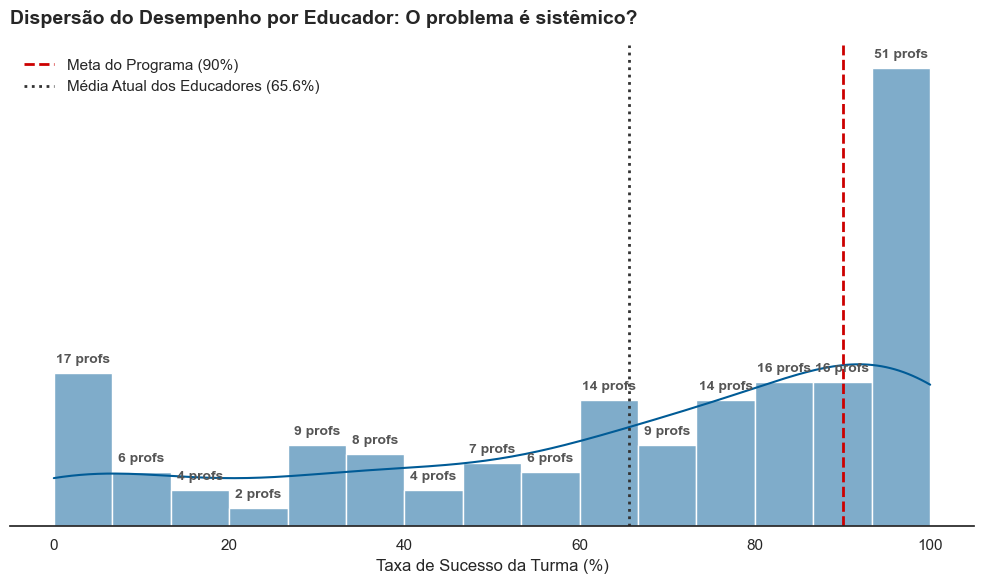

RESUMO DO FATOR DIDÁTICA:
-> Foram analisados 183 educadores (turmas com 5+ alunos ativos).
-> Apenas 61 educadores (33.3%) conseguiram fazer com que 90% ou mais de seus alunos atingissem a meta.


In [120]:
# Configuração visual padrão
sns.set_theme(style="white")

# 1. Agrupando por alfabetizador para calcular a taxa de sucesso média de suas turmas
# Usamos 'alfabetizador_x' que veio do arquivo pedagógico após o merge
desempenho_educador = df_plot.groupby('alfabetizador_x').agg(
    total_alunos=('cpf', 'count'),
    taxa_sucesso=('sucesso_f1', lambda x: x.mean() * 100)
).reset_index()

# 2. Filtrando educadores com pelo menos 5 alunos ativos para evitar distorções estatísticas 
# (ex: um professor com 1 único aluno que tirou nota boa teria 100% de sucesso "falso")
desempenho_educador = desempenho_educador[desempenho_educador['total_alunos'] >= 5]

# 3. Construção do Gráfico (Histograma com curva de densidade KDE)
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=desempenho_educador, x='taxa_sucesso', bins=15, color='#005b96', kde=True, ax=ax)

# 4. Adicionando linhas de referência (Storytelling)
media_atual = desempenho_educador['taxa_sucesso'].mean()
ax.axvline(x=90, color='#cc0000', linestyle='--', linewidth=2, label='Meta do Programa (90%)')
ax.axvline(x=media_atual, color='#333333', linestyle=':', linewidth=2, label=f'Média Atual dos Educadores ({media_atual:.1f}%)')

# 5. Aplicando princípios de Storytelling com Dados
sns.despine(left=True)
ax.get_yaxis().set_visible(False)
ax.set_title('Dispersão do Desempenho por Educador: O problema é sistêmico?', loc='left', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Taxa de Sucesso da Turma (%)', fontsize=12)
ax.legend(frameon=False, loc='upper left')

# Adicionando rótulos diretos nas barras do histograma (quantidade de professores)
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)} profs', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', 
                    color='#555555', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# 6. Resumo Executivo Impresso
educadores_na_meta = desempenho_educador[desempenho_educador['taxa_sucesso'] >= 90].shape[0]
total_educadores = desempenho_educador.shape[0]

print("RESUMO DO FATOR DIDÁTICA:")
print(f"-> Foram analisados {total_educadores} educadores (turmas com 5+ alunos ativos).")
print(f"-> Apenas {educadores_na_meta} educadores ({educadores_na_meta/total_educadores*100:.1f}%) conseguiram fazer com que 90% ou mais de seus alunos atingissem a meta.")


### 5.1 Os Pontos Fora da Curva: Educadores de Alta Performance

Apesar do desafio sistêmico evidenciado pela distribuição, identificamos um grupo de 61 educadores que conseguiram superar a meta estipulada pelo programa. 

Listar e mapear esses educadores é um passo estratégico. Eles representam as melhores práticas do estado de Sergipe. Compreender a didática que aplicam em sala de aula pode ser a chave para reestruturar os treinamentos e compartilhar métodos de sucesso com o restante da rede.


In [121]:
# 1. Filtrando os educadores de alta performance (Taxa >= 90%)
educadores_destaque = desempenho_educador[desempenho_educador['taxa_sucesso'] >= 90].copy()

# 2. Ordenando pelos melhores resultados e maior número de alunos
# Quem tem 100% de sucesso aparece primeiro. Para desempate, quem tem mais alunos ganha.
educadores_destaque = educadores_destaque.sort_values(
    by=['taxa_sucesso', 'total_alunos'], 
    ascending=[False, False]
)

# 3. Formatando a tabela para uma apresentação executiva (limpa e fácil de ler)
educadores_destaque = educadores_destaque.rename(columns={
    'alfabetizador_x': 'Nome do Educador',
    'total_alunos': 'Qtd. de Alunos Avaliados',
    'taxa_sucesso': 'Taxa de Sucesso (%)'
})

# Arredondando a taxa de sucesso para 1 casa decimal
educadores_destaque['Taxa de Sucesso (%)'] = educadores_destaque['Taxa de Sucesso (%)'].round(1)

print("🏆 Top Educadores que atingiram a Meta (Taxa >= 90%):")
# Mostrando os 15 primeiros para exemplo
display(educadores_destaque.head(15).style.background_gradient(cmap='Blues', subset=['Taxa de Sucesso (%)']))

# Caso queira exportar a lista completa para o Excel e enviar para a coordenação, 
# basta descomentar a linha abaixo e executar:
# educadores_destaque.to_excel('educadores_alta_performance.xlsx', index=False)

🏆 Top Educadores que atingiram a Meta (Taxa >= 90%):


,Nome do Educador,Qtd. de Alunos Avaliados,Taxa de Sucesso (%)
65,ICLEIA CHAGAS DA SILVA,101,100.000000
86,JOSEVAL SANTANA DA CRUZ,64,100.000000
52,FABIANA REGINA SOUZA SANTOS,58,100.000000
6,ALAN MICHEL MENDONÇA RIBEIRO,51,100.000000
170,SUY ANNE SANTOS LEITE,50,100.000000
45,ELIENE OLIVEIRA DA SILVA,45,100.000000
140,MÔNICA OLIVEIRA LIMA,36,100.000000
180,WELBERSON DE ALMEIDA SANTOS,30,100.000000
2,ADRIAN RAFAEL DOS SANTOS TORRES,29,100.000000
154,REGIANE DE MELO SILVA,29,100.000000


## 6A. Modelagem Preditiva (Machine Learning): Prevenção de Risco do Aluno

Após compreendermos os ofensores gerais, damos um passo em direção à inteligência antecipatória. Utilizamos o algoritmo de *Machine Learning* **Random Forest** para criar um sistema de alerta pedagógico precoce (Early Warning System).

**Como funciona:**
1. **O Treinamento:** Ensinamos o modelo utilizando o histórico das turmas já finalizadas (iniciadas em 27/04/2026). O algoritmo cruza as notas (Diagnóstica e Formativa 1), a Frequência e as 7 dimensões do Relatório Socioemocional para aprender os padrões ocultos que levam um aluno a não se alfabetizar (N1 ou N2 na Avaliação de Saída).
2. **A Descoberta:** Extraímos o "peso" de cada variável para o algoritmo, confirmando matematicamente quais características ou comportamentos específicos são os maiores gatilhos de risco.
3. **A Aplicação (O Resgate):** O modelo avalia os alunos das turmas que **ainda estão em andamento** e atribui uma probabilidade de fracasso a cada um, gerando uma lista acionável para a intervenção imediata de tutores e coordenadores.

MÉTRICAS DO MODELO PREDITIVO (Precisão na Base de Teste):
                          precision    recall  f1-score   support

Sucesso na Saída (N3/N4)       0.99      1.00      0.99       726
  Risco na Saída (N1/N2)       0.25      0.17      0.20         6

                accuracy                           0.99       732
               macro avg       0.62      0.58      0.60       732
            weighted avg       0.99      0.99      0.99       732



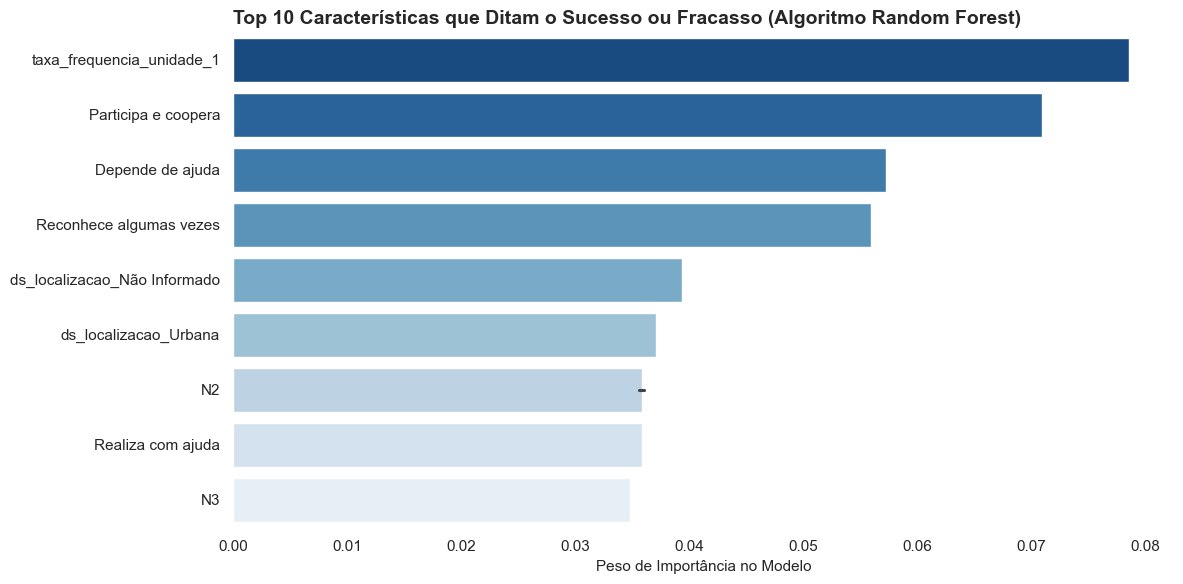


RESUMO DA PREDIÇÃO NAS TURMAS ATIVAS (Para Ação Imediata da Coordenação):
status_alerta
🟢 Seguro         3602
🟡 Risco Médio      23
Name: count, dtype: int64

🚨 Top 5 Alunos com Necessidade de Resgate Pedagógico Urgente:


,alfabetizando,turma,alfabetizador_x,prob_risco,status_alerta
1602,JOSE CARLOS DOS SANTOS,TURMA-28009851-0002,ROSEY MARY SANTANA,58.0%,🟡 Risco Médio
1938,GILSARIA ALVES DE SOUZA,TURMA-28010132-0007,TAMIRES ALVES SANTOS SANTANA,55.2%,🟡 Risco Médio
2156,GILSON GOMES DA SILVA,TURMA-28014081-0001,LETICIA OLIVEIRA SILVA,54.5%,🟡 Risco Médio
747,EMILLI MARTIRES DA SILVA,TURMA-28007158-0003,RAFAEL DA PAIXÃO SANTOS,53.8%,🟡 Risco Médio
903,STHEFANE KAROLAYNE NASCIMENTO SANTOS,TURMA-28007190-0007,MARIA IVANILDE DOS SANTOS,53.8%,🟡 Risco Médio


In [122]:
# Configuração visual
sns.set_theme(style="white")

# 1. Separar as bases (Turmas concluídas vs Em andamento)
df_concluido = df_limpo[df_limpo['dt_inicio'] == '2026-04-27'].copy()
df_ativo = df_limpo[df_limpo['dt_inicio'] != '2026-04-27'].copy()

# 2. Definir a variável alvo (Target) nas turmas concluídas
# Risco = 1 (Tirou N1 ou N2 na Saída), Sucesso = 0 (Tirou N3 ou N4)
df_concluido = df_concluido.dropna(subset=['diag_said_result_resum'])
df_concluido['risco_saida'] = df_concluido['diag_said_result_resum'].isin(['N1', 'N2']).astype(int)

# 3. Selecionar as Features (Variáveis Preditoras) incluindo todas as socioemocionais
features_categoricas = [
    'diag_entr_result_resum', 'forma_1_result_resum', 'ds_localizacao',
    'socio_entr_q1_resum', 'socio_entr_q2_resum', 'socio_entr_q3_resum',
    'socio_entr_q4_resum', 'socio_entr_q5_resum', 'socio_entr_q6_resum', 'socio_entr_q7_resum'
]
features_numericas = ['taxa_frequencia_unidade_1']
features = features_categoricas + features_numericas

# Filtrar nulos no df_ativo para manter a consistência da predição (apenas alunos com Formativa 1)
df_ativo = df_ativo.dropna(subset=['forma_1_result_resum']).copy()

X = df_concluido[features]
y = df_concluido['risco_saida']

# 4. Construção do Pipeline de Machine Learning
# Trata os vazios e converte as respostas de texto em variáveis binárias (0 e 1)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Sem_Info')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, features_numericas),
    ('cat', cat_transformer, features_categoricas)
])

# Random Forest com profundidade limitada (max_depth) para evitar overfitting e pesos balanceados
modelo_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced'))
])

# 5. Treinar e Avaliar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
modelo_rf.fit(X_train, y_train)
y_pred = modelo_rf.predict(X_test)

print("MÉTRICAS DO MODELO PREDITIVO (Precisão na Base de Teste):")
print(classification_report(y_test, y_pred, target_names=['Sucesso na Saída (N3/N4)', 'Risco na Saída (N1/N2)']))

# 6. Extrair a Importância das Variáveis para o Gráfico
cat_encoder = modelo_rf.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot']
cat_features_names = cat_encoder.get_feature_names_out(features_categoricas)
todas_features = features_numericas + list(cat_features_names)
importancias = modelo_rf.named_steps['classifier'].feature_importances_

# Limpando os nomes das variáveis criadas pelo OneHotEncoder para o gráfico ficar elegante
nomes_limpos = [nome.split('_resum_')[-1] if '_resum_' in nome else nome for nome in todas_features]

df_importancia = pd.DataFrame({'Característica do Aluno': nomes_limpos, 'Peso': importancias})
df_importancia = df_importancia.sort_values(by='Peso', ascending=False).head(10) # Top 10 ofensores

# Plotando
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df_importancia, x='Peso', y='Característica do Aluno', palette='Blues_r', ax=ax)
sns.despine(left=True, bottom=True)
ax.set_title('Top 10 Características que Ditam o Sucesso ou Fracasso (Algoritmo Random Forest)', loc='left', fontweight='bold', fontsize=14)
ax.set_xlabel('Peso de Importância no Modelo', fontsize=11)
ax.set_ylabel('')

# Anotações para storytelling
plt.tight_layout()
plt.show()

# 7. Predição nas Turmas Ativas (O Alerta)
# predict_proba retorna [prob_sucesso, prob_risco]. Queremos a coluna 1 (risco)
df_ativo['prob_risco'] = modelo_rf.predict_proba(df_ativo[features])[:, 1]
df_ativo['status_alerta'] = np.where(df_ativo['prob_risco'] >= 0.70, '🔴 Alto Risco', 
                                 np.where(df_ativo['prob_risco'] >= 0.40, '🟡 Risco Médio', '🟢 Seguro'))

print("\nRESUMO DA PREDIÇÃO NAS TURMAS ATIVAS (Para Ação Imediata da Coordenação):")
resumo = df_ativo['status_alerta'].value_counts()
print(resumo)

# Exibindo uma amostra da tabela acionável (os 5 alunos com maior risco mapeado)
tabela_alerta = df_ativo[['alfabetizando', 'turma', 'alfabetizador_x', 'prob_risco', 'status_alerta']]
tabela_alerta = tabela_alerta.sort_values(by='prob_risco', ascending=False)

print("\n🚨 Top 5 Alunos com Necessidade de Resgate Pedagógico Urgente:")
display(tabela_alerta.head(5).style.format({'prob_risco': '{:.1%}'}).background_gradient(cmap='Reds', subset=['prob_risco']))

# Descomente para gerar o relatório real em Excel
# tabela_alerta.to_excel('relatorio_alunos_risco_imediato.xlsx', index=False)


### A Anatomia do Risco: O que o Algoritmo Aprendeu?

A implementação do modelo *Random Forest* permitiu-nos passar de uma análise descritiva para uma visão preditiva. Os resultados gerados pelo modelo trazem conclusões críticas sobre os fatores que ditam o fracasso no programa e sobre a própria estrutura dos dados.

**1. O Desafio do Desbalanceamento (As Métricas do Modelo)**
As métricas do modelo revelam um fenómeno estatístico conhecido como "Desbalanceamento de Classes". 
* O modelo apresenta uma precisão global (`accuracy`) de 99%. Contudo, ao observar o relatório de classificação, notamos que a base de teste possuía 726 casos de "Sucesso" contra apenas 6 casos de "Risco" na Avaliação de Saída.
* Devido a esta assimetria massiva, o modelo tornou-se excecional a prever quem vai ter sucesso (Recall de 100%), mas teve grande dificuldade em identificar os raros casos de fracasso extremo na saída (Recall de 17%). Isto indica que, nas turmas que já concluíram o programa, a quase totalidade dos alunos atingiu a alfabetização mínima no final, tornando o "fracasso absoluto" um evento estatisticamente raro.

**2. Os Maiores Gatilhos de Risco (Feature Importance)**
Apesar do desbalanceamento, a árvore de decisão conseguiu isolar matematicamente as características que mais pesam na probabilidade de um aluno não se alfabetizar. O gráfico revela que:
* **Frequência (O Fator Crítico):** A `taxa_frequencia_unidade_1` é, isoladamente, a variável mais determinante. A ausência nas aulas da primeira unidade compromete de forma quase irrecuperável o percurso do aluno.
* **Comportamento e Dependência:** O algoritmo confirmou as nossas suspeitas da Etapa 3. Comportamentos como "Participa e coopera" (fator protetor), "Depende de ajuda" (fator de risco) e "Reconhece algumas vezes" a utilidade da leitura são os três fatores socioemocionais com maior peso na previsão do fracasso.
* **O Teto Metodológico:** Curiosamente, o nível N2 de entrada aparece com grande relevância, reforçando a dificuldade do programa em nivelar alunos com maiores deficiências iniciais.

**3. O Radar de Intervenção**
Ao aplicar este "cérebro" treinado às 3625 observações das turmas ativas, o algoritmo classificou 3602 alunos como "Seguros" e identificou **23 alunos em "Risco Médio"**. 
Estes 23 alunos (liderados por perfis com cerca de 58% de probabilidade matemática de reprovação) representam os alvos imediatos para a atuação da coordenação. É com estes alunos que a equipa de tutores deve intervir amanhã, aplicando estratégias de retenção, reforço escolar e contextualização da utilidade da leitura.

## 6B. Matriz de Capacitação: Priorização Estratégica de Educadores

Enquanto o sistema de alerta atua no resgate imediato do aluno, o sucesso a longo prazo do programa exige a requalificação contínua dos educadores. 

Cruzamos os dois maiores ofensores identificados na nossa análise para criar uma **Matriz de Priorização**:
* **Desafio Pedagógico (Eixo X):** O percentual de alunos na turma com defasagem severa de entrada (Nível 1).
* **Desafio de Contextualização (Eixo Y):** O percentual de alunos na turma que não reconhecem a utilidade prática da leitura.

As linhas pontilhadas representam a média estadual. O nosso foco absoluto é o **Quadrante Superior Direito (Zona Crítica)**. Para garantir a usabilidade deste relatório, geramos abaixo duas visões: uma interativa para exploração em tela e uma visão estática otimizada para exportação em apresentações executivas, com o destaque nominal das 5 prioridades urgentes.

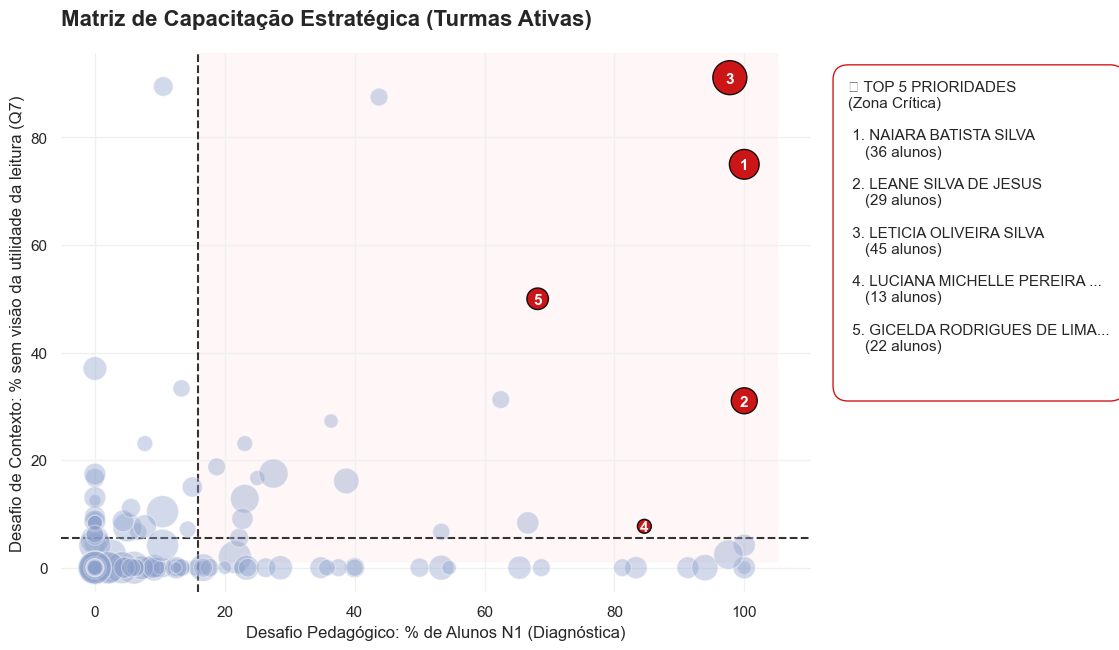


🚨 Top 10 Educadores para Ação Imediata da Coordenação Pedagógica:


,alfabetizador_x,total_alunos,pct_n1,pct_sem_contexto
131,NAIARA BATISTA SILVA,36,100.0%,75.0%
95,LEANE SILVA DE JESUS,29,100.0%,31.0%
96,LETICIA OLIVEIRA SILVA,45,97.8%,91.1%
100,LUCIANA MICHELLE PEREIRA SANTOS,13,84.6%,7.7%
55,GICELDA RODRIGUES DE LIMA,22,68.2%,50.0%
84,JULIANA GOMES DE LIMA DUARTE,24,66.7%,8.3%
3,ADRYELLE SANTOS LINO,16,62.5%,31.2%
44,ELISANGELA LISBOA DE MORAES MENDONCA,15,53.3%,6.7%
124,MARÍLIA GRACIELA RIBEIRO DE ARAÚJO,16,43.8%,87.5%
80,JOSILENE CORREIA SANTOS,31,38.7%,16.1%


In [123]:
# 1. Preparação dos Dados
df_ativo_matriz = df_limpo[df_limpo['dt_inicio'] != '2026-04-27'].copy()
df_ativo_matriz['is_n1'] = (df_ativo_matriz['diag_entr_result_resum'] == 'N1').astype(int)
df_ativo_matriz['is_sem_contexto'] = (df_ativo_matriz['socio_entr_q7_resum'] == 'Não reconhece').astype(int)

matriz_capacitacao = df_ativo_matriz.groupby('alfabetizador_x').agg(
    total_alunos=('cpf', 'count'),
    pct_n1=('is_n1', lambda x: x.mean() * 100),
    pct_sem_contexto=('is_sem_contexto', lambda x: x.mean() * 100)
).reset_index()

# Filtrando turmas pequenas (mínimo 5 alunos)
matriz_capacitacao = matriz_capacitacao[matriz_capacitacao['total_alunos'] >= 5]
corte_x = matriz_capacitacao['pct_n1'].mean()
corte_y = matriz_capacitacao['pct_sem_contexto'].mean()

# Criando a coluna de Status e isolando o Top 5
matriz_capacitacao['Status'] = np.where(
    (matriz_capacitacao['pct_n1'] > corte_x) & (matriz_capacitacao['pct_sem_contexto'] > corte_y),
    'Prioridade 1 (Zona Crítica)', 'Demais Educadores'
)

zona_critica = matriz_capacitacao[matriz_capacitacao['Status'] == 'Prioridade 1 (Zona Crítica)'].copy()
zona_critica = zona_critica.sort_values(by=['pct_n1', 'pct_sem_contexto'], ascending=False)
top5_educadores = zona_critica.head(5).copy()
top5_educadores['Rank'] = range(1, 6)

# ===================================================================
# GRÁFICO 1: PLOTLY (Interativo para o Jupyter)
# ===================================================================
fig_plotly = px.scatter(
    matriz_capacitacao, x='pct_n1', y='pct_sem_contexto', size='total_alunos',
    color='Status', hover_name='alfabetizador_x',
    hover_data={'Status': False, 'pct_n1': ':.1f', 'pct_sem_contexto': ':.1f', 'total_alunos': True},
    color_discrete_map={'Prioridade 1 (Zona Crítica)': '#cc0000', 'Demais Educadores': '#005b96'},
    size_max=35,
    labels={'pct_n1': '% de Alunos N1', 'pct_sem_contexto': '% Alunos sem contexto (Q7)'},
    title='<b>Matriz Interativa</b><br><sup>Passe o mouse sobre as bolhas para detalhes</sup>'
)
fig_plotly.add_vline(x=corte_x, line_dash="dash", line_color="#333333")
fig_plotly.add_hline(y=corte_y, line_dash="dash", line_color="#333333")
fig_plotly.update_layout(plot_bgcolor='white', margin=dict(t=80))
fig_plotly.update_xaxes(showline=True, linecolor='black', gridcolor='#f0f0f0')
fig_plotly.update_yaxes(showline=True, linecolor='black', gridcolor='#f0f0f0')
fig_plotly.show()

# ===================================================================
# GRÁFICO 2: MATPLOTLIB/SEABORN (Estático otimizado para PPT/PDF)
# ===================================================================
sns.set_theme(style="whitegrid", rc={"grid.color": "#f0f0f0"})
fig, ax = plt.subplots(figsize=(12, 7))

# Fundo avermelhado para a Zona Crítica
ax.axvspan(corte_x, matriz_capacitacao['pct_n1'].max() + 5, 
           ymin=corte_y / (matriz_capacitacao['pct_sem_contexto'].max() + 5), 
           ymax=1, color='#ffe6e6', alpha=0.3, zorder=0)

# Plot da base inteira (em cinza/azul claro para não tirar a atenção)
sns.scatterplot(data=matriz_capacitacao, x='pct_n1', y='pct_sem_contexto', size='total_alunos', 
                sizes=(50, 600), alpha=0.4, color='#8da0cb', edgecolor='white', ax=ax, legend=False, zorder=2)

# Plot específico do Top 5 (Destaque em Vermelho Forte)
sns.scatterplot(data=top5_educadores, x='pct_n1', y='pct_sem_contexto', size='total_alunos', 
                sizes=(100, 600), alpha=0.9, color='#cc0000', edgecolor='black', ax=ax, legend=False, zorder=3)

# Adicionando os números de 1 a 5 no centro das bolhas do Top 5
for _, row in top5_educadores.iterrows():
    ax.annotate(str(int(row['Rank'])), xy=(row['pct_n1'], row['pct_sem_contexto']),
                xytext=(0, -1), textcoords="offset points", ha='center', va='center', 
                color='white', fontweight='bold', fontsize=11, zorder=4)

# Linhas de Corte
ax.axvline(corte_x, color='#333333', linestyle='--', linewidth=1.5, zorder=1)
ax.axhline(corte_y, color='#333333', linestyle='--', linewidth=1.5, zorder=1)

# Estilização do Eixo
sns.despine(left=True, bottom=True)
ax.set_title('Matriz de Capacitação Estratégica (Turmas Ativas)', loc='left', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Desafio Pedagógico: % de Alunos N1 (Diagnóstica)', fontsize=12)
ax.set_ylabel('Desafio de Contexto: % sem visão da utilidade da leitura (Q7)', fontsize=12)

# Construção da Caixa de Legenda Lateral (Caixa de Texto Executiva)
texto_legenda = "🚨 TOP 5 PRIORIDADES\n(Zona Crítica)\n\n"
for _, row in top5_educadores.iterrows():
    # Limita o tamanho do nome do professor para não quebrar a caixa
    nome_prof = str(row['alfabetizador_x'])[:25] + ('...' if len(str(row['alfabetizador_x'])) > 25 else '')
    texto_legenda += f" {int(row['Rank'])}. {nome_prof}\n    ({row['total_alunos']} alunos)\n\n"

# Posiciona o texto fora da área do gráfico (x=1.05)
plt.text(1.05, 0.95, texto_legenda, transform=ax.transAxes, fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=1', facecolor='#ffffff', edgecolor='#cc0000', alpha=0.9))

# Ajuste de margens para a caixa de texto caber na imagem exportada
plt.subplots_adjust(right=0.75)
plt.show()

print("\n🚨 Top 10 Educadores para Ação Imediata da Coordenação Pedagógica:")
display(zona_critica[['alfabetizador_x', 'total_alunos', 'pct_n1', 'pct_sem_contexto']].head(10).style.format({
    'pct_n1': '{:.1f}%', 
    'pct_sem_contexto': '{:.1f}%'
}).background_gradient(cmap='Reds'))


### Interpretação da Matriz de Priorização

A visualização da Matriz de Capacitação traduz a complexidade da rede de educadores numa ferramenta de decisão clara e acionável.

Observando a dispersão das turmas, extraímos conclusões críticas para a gestão do programa:
1. **A Maioria Silenciosa (Zona de Conforto):** A grande concentração de bolhas no canto inferior esquerdo indica que a maior parte dos educadores lida com turmas onde o desafio inicial é moderado ou baixo (poucos alunos N1 e boa compreensão do contexto prático da leitura).
2. **A Tempestade Perfeita (Zona Crítica):** No quadrante superior direito, isolamos os profissionais que enfrentam o cenário mais adverso possível. Eles possuem turmas onde quase 100% dos alunos entraram sem nenhum conhecimento prévio (N1) e, simultaneamente, apresentam altíssimos índices de desconexão com a utilidade prática da alfabetização.
3. **Foco Cirúrgico (Top 5):** O gráfico aponta exatamente onde o apoio pedagógico deve desembarcar amanhã. Educadoras como Leticia Oliveira Silva (bolha 3) e Naiara Batista Silva (bolha 1), que gerem turmas grandes (45 e 36 alunos, respetivamente) sob condições de extremo desafio, não podem ser tratadas com a mesma régua de formação que um educador da zona de conforto. Elas precisam de suporte imediato, materiais adaptados e metodologias focadas em contextualização de adultos.

## 7. Síntese Executiva e Recomendações (Respondendo ao Problema de Negócio)

Este projeto de análise de dados foi iniciado com o objetivo de investigar a razão pela qual a meta de 90% de sucesso não foi atingida na Atividade Formativa 1 do Programa Brasil Alfabetizado em Sergipe. Com base na modelagem preditiva e na análise exploratória de milhares de registos, apresentamos as respostas oficiais e as recomendações estratégicas:

**1. Qual(is) a(s) razão(ões) que melhor explicam a meta de 90% na Formativa 1 não ter sido atingida?**
A falha no atingimento da meta não se deve a um único fator, mas sim a uma combinação estrutural: a metodologia atual não possui "tempo de rampa" suficiente para alunos que ingressam com defasagem total (N1), e o programa sofre de uma execução altamente polarizada. Enquanto uma elite de educadores consegue atingir 100% de sucesso, cerca de 66% da rede não atinge a meta, evidenciando uma falha sistêmica na capacitação e padronização didática.

**2. Há alguma relação entre a meta não ter sido atingida e o Relatório Socioemocional?**
Sim, uma relação profunda, mas não onde se esperava. A simples "desmotivação" (Q1) afeta pouco a aprovação. O verdadeiro gargalo é a **Falta de Contextualização (Q7)**. Alunos adultos que não enxergam a utilidade prática da leitura para o seu dia a dia fracassam drasticamente. A falta de autonomia (Q3) e a insegurança perante desafios (Q4) também são gatilhos críticos eleitos pelo nosso modelo de *Machine Learning*.

**3. Há alguma relação entre a meta não ter sido atingida e a Diagnóstica de Entrada?**
Sim, este é um dos maiores ofensores. A matriz de evolução provou que apenas 21% dos alunos que entraram no Nível 1 alcançaram o nível satisfatório na Formativa 1. O programa exige um "salto" cognitivo que o aluno leigo não consegue dar num espaço de tempo tão curto sem apoio especializado.

**4. Há relação com os índices de frequência, número de alunos ou didática do alfabetizador?**
* **Frequência:** É o pilar central. O algoritmo preditivo apontou a frequência na Unidade 1 como a principal variável que dita o sucesso ou o risco de fracasso.
* **Didática:** É o maior gargalo logístico. Apenas 33,3% dos educadores conseguiram bater a meta, e mapeamos dezenas deles atuando na "Zona Crítica", necessitando de intervenção imediata.

---

### 🎯 Plano de Ação Recomendado (Próximos Passos)

1. **Ativação do Radar de Risco:** Enviar imediatamente a lista de alunos sinalizados como "Risco Médio/Alto" nas turmas ativas para os coordenadores locais aplicarem protocolos de resgate.
2. **Capacitação Cirúrgica:** Utilizar a *Matriz de Capacitação* para convocar o "Top 5" (e demais professores da Zona Crítica) para um workshop focado em estratégias de ensino contextualizado para adultos.
3. **Revisão Metodológica:** Avaliar junto à equipa pedagógica a flexibilização do cronograma da Unidade 1 para turmas compostas maioritariamente por alunos N1.